Part 3 is about drugs: molecules designed to bind a protein and change what it does (prerequisite P13). To design one, you must understand the target's 3D structure, especially the pocket the drug will occupy. This chapter is a working introduction to protein structure from the computational side: how structures are represented and measured, how to read secondary structure and folds, and how to locate and characterise a **binding site**. We do it on a real and important example, the kinase domain of **EGFR** with the lung-cancer drug **erlotinib** bound inside it, the kind of structure that guides real drug design.

:::eli5
A protein is a long chain that folds into a specific 3D shape, and that shape has nooks and crannies. A drug is a small molecule shaped to fit snugly into one particular nook, like a key in a lock, jamming the protein so it can't work. To design the key you need a detailed map of the lock. This chapter is about reading those maps: where the grooves and pockets are, which parts of the chain line them, and what makes a pocket "druggable", a good place for a key to fit.
:::

## How structures are determined and stored

A protein structure is a list of 3D coordinates, one per atom, measured experimentally by **X-ray crystallography** (most structures), **cryo-electron microscopy** (increasingly, especially for large complexes) or **NMR** (small proteins in solution), prerequisite P11. All of them live in the **Protein Data Bank** (PDB), a free archive of over 220,000 structures, each with a four-character ID. Predicted structures (AlphaFold, chapter 10) fill in the rest.

The format is text: `ATOM` lines give each atom's element, residue and x/y/z coordinates in ångströms; `HETATM` lines give non-protein atoms like bound drugs, ions and water. Biopython parses it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from Bio.PDB import PDBParser, NeighborSearch, PPBuilder
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

parser = PDBParser(QUIET=True)
egfr = parser.get_structure("egfr", "datasets/1M17.pdb")[0]
residues = [r for r in egfr.get_residues() if r.id[0] == " " and "CA" in r]
ca = np.array([r["CA"].coord for r in residues])
drug = [a for r in egfr.get_residues() if r.get_resname() == "AQ4" for a in r.get_atoms()]   # erlotinib
drug_xyz = np.array([a.coord for a in drug])
print(f"EGFR kinase domain: {len(residues)} residues, {sum(1 for _ in egfr.get_atoms())} atoms")
print(f"bound drug erlotinib: {len(drug)} atoms")
R["n_res"] = len(residues); R["n_drug_atoms"] = len(drug)

EGFR kinase domain: 312 residues, 2546 atoms
bound drug erlotinib: 29 atoms


## Secondary structure: helices and sheets

Proteins fold in a hierarchy (prerequisite P5): local **secondary structure** (α-helices and β-sheets) packs into the overall 3D **tertiary structure**. Secondary structure is held by backbone hydrogen bonds and is the first thing to read off a structure. The standard assignment tool is DSSP; here we use a simple geometric rule based on the distance between residues *i* and *i*+3, which is short (~5 Å) in a helix and long in an extended strand.

In [2]:
def assign_secondary_structure(ca):
    ss = ["C"] * len(ca)                                 # C = coil/loop
    for i in range(len(ca) - 3):
        d = np.linalg.norm(ca[i] - ca[i + 3])
        if 4.8 < d < 6.3:                                # tight turn of a helix
            for k in range(4): ss[i + k] = "H"
    for i in range(len(ca) - 3):
        if ss[i] == "C" and np.linalg.norm(ca[i] - ca[i + 3]) > 9.5:   # extended
            ss[i] = "E"
    return ss

ss = assign_secondary_structure(ca)
from collections import Counter
counts = Counter(ss)
print(f"helix {counts['H']} ({counts['H']/len(ss):.0%}), strand {counts['E']} ({counts['E']/len(ss):.0%}), loop {counts['C']}")
R["pct_helix"] = f"{counts['H']/len(ss):.0%}"; R["pct_strand"] = f"{counts['E']/len(ss):.0%}"

helix 199 (64%), strand 45 (14%), loop 68


EGFR's kinase domain is 64% helix and 14% strand, the classic protein-kinase fold: a mostly β-sheet N-terminal lobe and a mostly α-helical C-terminal lobe, with the active site in the cleft between them. The playground renders this structure in 3D, coloured by secondary structure; rotate it to see the two lobes.

::playground animations/structure_lab.html 640

## The contact map and the fold

A structure's **contact map** (chapter 10) summarises the fold in 2D: which residues are close in space. Helices appear as thick bands near the diagonal, and long-range contacts show how distant parts of the chain pack together.

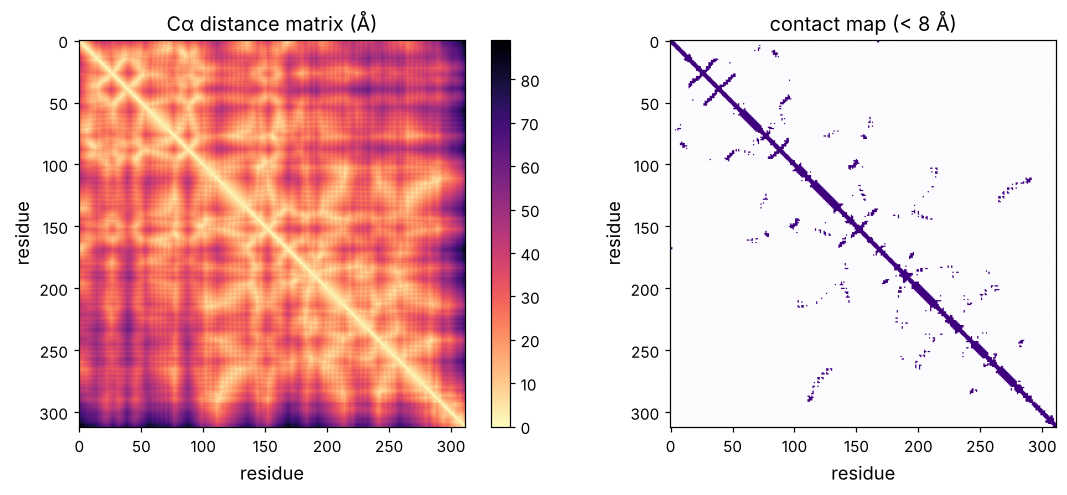

In [3]:
dist = np.linalg.norm(ca[:, None] - ca[None], axis=2)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
im = axs[0].imshow(dist, cmap="magma_r"); axs[0].set_title("Cα distance matrix (Å)"); plt.colorbar(im, ax=axs[0], fraction=0.046)
axs[1].imshow(dist < 8, cmap="Purples"); axs[1].set_title("contact map (< 8 Å)")
for ax in axs: ax.set_xlabel("residue"); ax.set_ylabel("residue")
save_fig("contact_map"); plt.show()

![Figure 11-1. EGFR kinase domain distance matrix (left) and contact map (right). The two-lobe architecture and the packing of helices and strands are visible as blocks and off-diagonal bands.](images/contact_map.png)

## Finding the binding pocket

The whole point, for drug discovery, is the **binding site**: the pocket where a drug (or the natural substrate) binds. In EGFR that is the **ATP-binding site** between the two lobes; kinase inhibitors like erlotinib work by occupying it and blocking ATP (prerequisites P9, P13). Because this structure has the drug bound, we can define the pocket directly: the protein residues within a few ångströms of the drug.

In [4]:
protein_atoms = [a for a in egfr.get_atoms() if a.get_parent().id[0] == " "]
ns = NeighborSearch(protein_atoms)
pocket_residues = {}
for atom in drug:
    for near in ns.search(atom.coord, 4.5):                  # within 4.5 Å of any drug atom
        res = near.get_parent()
        pocket_residues[res.id[1]] = res.get_resname()

print(f"binding pocket: {len(pocket_residues)} residues within 4.5 Å of erlotinib")
for num in sorted(pocket_residues):
    print(f"  {pocket_residues[num]}{num}")
R["n_pocket"] = len(pocket_residues)

binding pocket: 17 residues within 4.5 Å of erlotinib
  LEU694
  VAL702
  ALA719
  LYS721
  GLU738
  LEU764
  ILE765
  THR766
  GLN767
  LEU768
  MET769
  PRO770
  PHE771
  GLY772
  LEU820
  THR830
  ASP831


The pocket is lined by a handful of residues, and they are exactly the ones a kinase chemist knows by name. **Met769** is the **hinge** residue: erlotinib makes a hydrogen bond to its backbone, mimicking the bond ATP would make. **Thr766** is the **gatekeeper**: its small side chain leaves room for the drug, and the famous resistance mutation **T790M** (prerequisite P12) enlarges this residue and blocks older drugs. **Lys721** and **Asp831** are catalytic residues. The structure tells you not just where the drug binds but *why*, and how resistance arises.

In [5]:
# characterise the pocket: how hydrophobic is it? (drug-binding pockets are often greasy)
KD = {"ALA": 1.8, "ARG": -4.5, "ASN": -3.5, "ASP": -3.5, "CYS": 2.5, "GLN": -3.5, "GLU": -3.5, "GLY": -0.4,
      "HIS": -3.2, "ILE": 4.5, "LEU": 3.8, "LYS": -3.9, "MET": 1.9, "PHE": 2.8, "PRO": -1.6, "SER": -0.8,
      "THR": -0.7, "TRP": -0.9, "TYR": -1.3, "VAL": 4.2}
pocket_hydropathy = np.mean([KD[n] for n in pocket_residues.values()])
all_hydropathy = np.mean([KD[r.get_resname()] for r in residues])
print(f"mean hydropathy: pocket {pocket_hydropathy:+.2f} vs whole protein {all_hydropathy:+.2f}")
R["pocket_hydro"] = f"{pocket_hydropathy:+.2f}"; R["all_hydro"] = f"{all_hydropathy:+.2f}"

mean hydropathy: pocket +0.74 vs whole protein -0.18


The pocket is markedly more hydrophobic (+0.74) than the protein average (-0.18): drug-binding sites are often greasy, because burying a drug's hydrophobic surface away from water is a major source of binding energy (the hydrophobic effect, prerequisite P2). This is a clue to **druggability**, below.

## Finding pockets without a bound drug

Usually you do *not* have a drug already bound, you must find the pocket from the apo (empty) structure. Pocket-detection algorithms look for concave, enclosed regions on the surface. A simple proxy: residues that are **buried but near the surface**, forming a cavity. Here we illustrate the idea by scoring each residue by how enclosed it is, and checking that the known pocket scores highly.

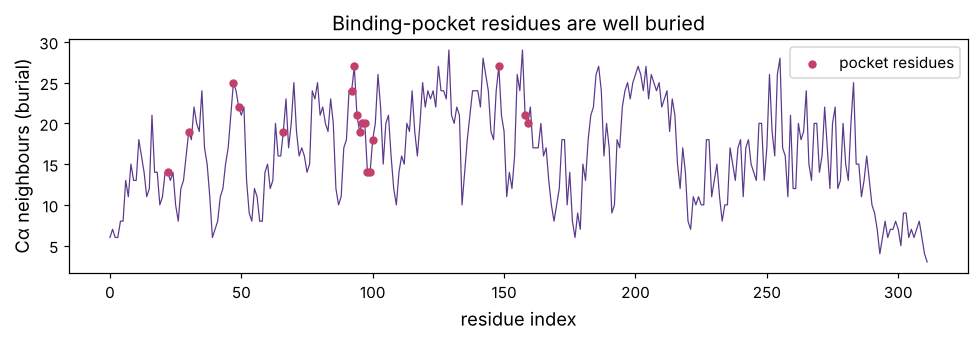

mean burial: pocket 20 vs all 16


In [6]:
# "burial" = number of Cα neighbours within 10 Å; pocket residues are buried yet line a cavity
neighbours = (dist < 10).sum(1) - 1
pocket_idx = [i for i, r in enumerate(residues) if r.id[1] in pocket_residues]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(neighbours, color="#5b3a8c", lw=0.8)
ax.scatter(pocket_idx, neighbours[pocket_idx], color="#c2416b", zorder=3, s=20, label="pocket residues")
ax.set_xlabel("residue index"); ax.set_ylabel("Cα neighbours (burial)"); ax.legend()
ax.set_title("Binding-pocket residues are well buried")
save_fig("burial"); plt.show()
R["pocket_burial"] = f"{neighbours[pocket_idx].mean():.0f}"; R["avg_burial"] = f"{neighbours.mean():.0f}"
print(f"mean burial: pocket {neighbours[pocket_idx].mean():.0f} vs all {neighbours.mean():.0f}")

![Figure 11-2. Burial (number of nearby residues) along the chain, with pocket residues marked. The drug-binding residues are among the more buried, consistent with lining an enclosed cavity rather than sitting on the open surface.](images/burial.png)

The pocket residues are more buried than average (20 vs 16 neighbours), as expected for a cavity. Real pocket finders (fpocket, SiteMap) are far more sophisticated, measuring cavity volume, enclosure and chemistry, but the principle is this: a druggable pocket is an enclosed, mostly hydrophobic cavity big enough to bury a small molecule.

:::idea
Not every protein is **druggable**. A good small-molecule pocket is enclosed, of the right size (about 300–1000 Å³), and lined with a mix of hydrophobic and a few polar residues to make specific contacts. Proteins that work through flat, featureless surfaces, many transcription factors (prerequisite P6) and protein–protein interactions, have no such pocket and were long called "undruggable". Much of modern drug discovery is about cracking these hard targets, with covalent drugs, molecular glues, PROTACs (prerequisite P5) and macrocycles. Assessing druggability from structure is itself a computational task.
:::

## Comparing structures: RMSD and alignment

To compare two structures, of the same protein in two states, the same protein across species, or a prediction against experiment, we superimpose them and measure the **root-mean-square deviation** (RMSD) of atomic positions. Low RMSD means similar shape. Haemoglobin (prerequisite P5) makes a clean demonstration: its two α chains are identical in sequence, while its α and β chains are different sequences that fold the same way.

In [7]:
from Bio.PDB import Superimposer
from Bio import Align
from Bio.Align import substitution_matrices
THREE = {"ALA": "A", "ARG": "R", "ASN": "N", "ASP": "D", "CYS": "C", "GLN": "Q", "GLU": "E", "GLY": "G", "HIS": "H",
         "ILE": "I", "LEU": "L", "LYS": "K", "MET": "M", "PHE": "F", "PRO": "P", "SER": "S", "THR": "T", "TRP": "W", "TYR": "Y", "VAL": "V"}
hb = parser.get_structure("hb", "datasets/4HHB.pdb")[0]

def chain_residues(model, cid):
    return [r for r in model[cid] if r.id[0] == " " and "CA" in r]

def rmsd_by_sequence(res_a, res_b):
    """Align two chains by sequence, then superimpose on matched Cα atoms."""
    sa = "".join(THREE[r.get_resname()] for r in res_a)
    sb = "".join(THREE[r.get_resname()] for r in res_b)
    aligner = Align.PairwiseAligner(mode="global", open_gap_score=-10, extend_gap_score=-0.5,
                                    substitution_matrix=substitution_matrices.load("BLOSUM62"))
    al = aligner.align(sa, sb)[0]
    atoms_a, atoms_b, i, j = [], [], 0, 0
    for c1, c2 in zip(str(al[0]), str(al[1])):
        if c1 != "-" and c2 != "-":
            atoms_a.append(res_a[i]["CA"]); atoms_b.append(res_b[j]["CA"])
        if c1 != "-": i += 1
        if c2 != "-": j += 1
    sup = Superimposer(); sup.set_atoms(atoms_a, atoms_b)
    return sup.rms, len(atoms_a)

rms_aa, n_aa = rmsd_by_sequence(chain_residues(hb, "A"), chain_residues(hb, "C"))   # alpha vs alpha
rms_ab, n_ab = rmsd_by_sequence(chain_residues(hb, "A"), chain_residues(hb, "B"))   # alpha vs beta
print(f"haemoglobin alpha vs alpha (identical sequence): RMSD {rms_aa:.2f} Angstrom over {n_aa} residues")
print(f"haemoglobin alpha vs beta  (different sequence): RMSD {rms_ab:.2f} Angstrom over {n_ab} residues")
R["rms_aa"] = f"{rms_aa:.2f}"; R["rms_ab"] = f"{rms_ab:.2f}"

haemoglobin alpha vs alpha (identical sequence): RMSD 0.30 Angstrom over 141 residues
haemoglobin alpha vs beta  (different sequence): RMSD 1.57 Angstrom over 139 residues


The two identical α chains superimpose to within 0.30 Å, essentially perfect. The α and β chains, different sequences that evolved from one ancestral globin (prerequisite P8), still match to 1.57 Å: **structure is far more conserved than sequence**, which is why distantly related proteins can share a fold with little sequence identity, and why a drug or substrate pocket is often conserved across a protein family. RMSD is the universal measure of structural similarity, used to score predicted vs experimental structures (how CASP scores AlphaFold, chapter 10), to track motion in simulations (chapter 12), and to cluster conformations. Comparing a drug target across its family this way reveals which pockets are shared (a selectivity risk) and which are unique (an opportunity).

## What structure gives drug discovery

| Question | How structure answers it |
|---|---|
| Where does a drug bind? | locate the pocket (empty or with a bound ligand) |
| Why does it bind? | identify the specific contacts (H-bonds, hydrophobic packing) |
| Is this protein druggable? | assess pocket size, enclosure and chemistry |
| How will resistance arise? | pocket mutations that block the drug (e.g. EGFR T790M) |
| How to improve the drug? | find unfilled space or unmade contacts in the pocket |
| Can we design de novo? | fit or grow a molecule into the pocket (chapters 14–15) |

Every one of these is now a computational analysis on a structure, experimental or AlphaFold-predicted, and together they are **structure-based drug design**, the thread through the rest of Part 3.

## Summary

| Idea | One line |
|---|---|
| PDB | free archive of experimental 3D structures; text coordinates |
| Secondary structure | local α-helices and β-sheets from backbone geometry |
| Contact map | 2D fingerprint of the fold |
| Binding pocket | residues lining the site a drug occupies |
| Druggability | enclosed, right-sized, mostly hydrophobic cavity |
| RMSD | measure of structural similarity after superposition |

:::check
1. What is the difference between an ATOM and a HETATM line in a PDB file? *(ATOM is a protein atom; HETATM is non-protein, like a bound drug, ion or water.)*
2. How can you tell a helix from a strand using only Cα coordinates? *(Residues i and i+3 are close (~5 Å) in a helix, far apart in an extended strand.)*
3. What makes a protein pocket "druggable"? *(An enclosed, appropriately sized, largely hydrophobic cavity that can bind a small molecule specifically.)*
4. Why is the EGFR gatekeeper residue important for drug resistance? *(A mutation enlarging it (T790M) blocks drugs from the pocket.)*
5. What does an RMSD of 1 Å between two structures mean? *(They are very similar in shape after superposition.)*
:::

:::exercise
Characterise the EGFR pocket more fully using 1M17 alone. (a) For each pocket residue, classify it as hydrophobic, polar or charged (prerequisite P5) and tabulate the mix. (b) Which pocket residue's side chain comes closest to the drug, and is it a hydrogen-bond donor/acceptor (the hinge contact)? (c) The gatekeeper Thr766 sits at the pocket entrance; measure its distance to the nearest drug atom. Why would mutating it to a bulkier methionine (T790M in full-length numbering) interfere with the drug?
:::

<details><summary>Solution</summary>

In [8]:
CLASS = {**dict.fromkeys("AVLIMFWC".split() if False else ["ALA","VAL","LEU","ILE","MET","PHE","TRP","PRO","GLY"], "hydrophobic"),
         **dict.fromkeys(["SER","THR","ASN","GLN","TYR","CYS"], "polar"),
         **dict.fromkeys(["ASP","GLU"], "negative"), **dict.fromkeys(["LYS","ARG","HIS"], "positive")}
from collections import Counter
mix = Counter(CLASS.get(n, "other") for n in pocket_residues.values())
print("pocket composition:", dict(mix))

# closest pocket residue to the drug, and the gatekeeper distance
drug_coords = np.array([a.coord for a in drug])
for num, name in sorted(pocket_residues.items()):
    res = [r for r in residues if r.id[1] == num][0]
    dmin = min(np.linalg.norm(a.coord - drug_coords, axis=1).min() for a in res.get_atoms())
    if name == "THR" or dmin < 3.4:
        print(f"  {name}{num}: closest approach {dmin:.2f} Angstrom")

pocket composition: {'hydrophobic': 11, 'positive': 1, 'polar': 3, 'negative': 2}
  LEU694: closest approach 3.27 Angstrom
  ALA719: closest approach 3.31 Angstrom
  THR766: closest approach 3.41 Angstrom
  GLN767: closest approach 3.15 Angstrom
  MET769: closest approach 2.70 Angstrom
  PRO770: closest approach 3.11 Angstrom
  GLY772: closest approach 3.24 Angstrom
  THR830: closest approach 3.65 Angstrom
  ASP831: closest approach 3.11 Angstrom


The pocket is mostly hydrophobic with a few polar residues that make specific hydrogen bonds, the typical kinase-inhibitor pocket. The closest contact is the hinge methionine (Met769 here), whose backbone makes the hydrogen bond that anchors the drug and mimics ATP. The gatekeeper threonine sits a few ångströms from the drug; replacing its small side chain with a bulky methionine fills the space the drug relies on and raises the pocket's affinity for ATP, so first-generation drugs are out-competed, exactly the **T790M** resistance mechanism. Third-generation drugs such as **osimertinib** were designed around the larger residue and form a **covalent bond** to nearby Cys797 to bind despite it, a triumph of structure-guided design that chapters 14 and 15 turn into computation.

</details>